
Результати оцінювання ResNet18
Accuracy:  0.7644
Precision: 0.7314
Recall:    0.9846
F1-score:  0.8393

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.94      0.40      0.56       234
   PNEUMONIA       0.73      0.98      0.84       390

    accuracy                           0.76       624
   macro avg       0.84      0.69      0.70       624
weighted avg       0.81      0.76      0.73       624



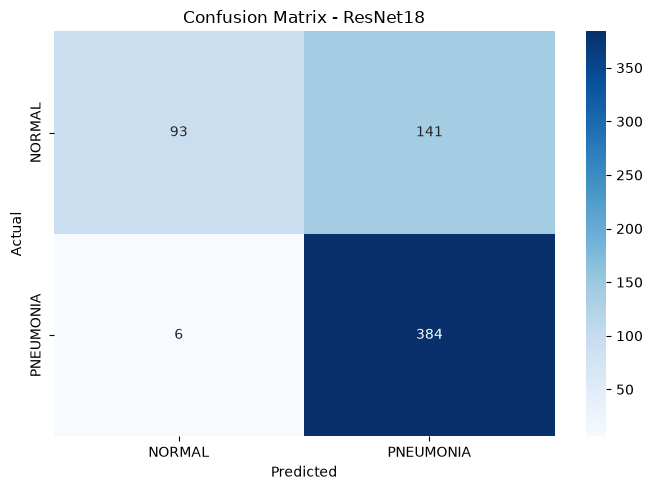

In [2]:

import torch
import torch.nn as nn
import torchvision.models as models

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from dataset import test_loader, class_names


# 1. Вибір пристрою
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# 2. Створення архітектури ResNet18
model = models.resnet18(weights=None)

model.fc = nn.Linear(
    model.fc.in_features,
    len(class_names)
)


# 3. Завантаження ваг
checkpoint = torch.load(
    "pneumonia_resnet18.pth",
    map_location=device,
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(device)

model.eval()


# 4. Отримання передбачень
all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_predictions.extend(
            predicted.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )


# 5. Обчислення метрик
accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision = precision_score(
    all_labels,
    all_predictions,
    pos_label=1,
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    pos_label=1,
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    pos_label=1,
    zero_division=0
)


# 6. Виведення результатів
print("\nРезультати оцінювання ResNet18")

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")


# 7. Детальний звіт
print("\nClassification Report:")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=class_names,
        zero_division=0
    )
)


# 8. Confusion Matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Confusion Matrix - ResNet18")

plt.tight_layout()

plt.savefig(
    "confusion_matrix.png",
    dpi=300
)

plt.show()
